# Our four-qubit ring QNN — understand it, run it, explain it
**Qiskit Fall Fest EMSI · Crop classification · Research notebook**

This notebook focuses on **one model: our four-qubit ring QNN**. It uses the
existing verified implementation, real crop data and saved checkpoints. We keep
four useful visuals: **the circuit, its training curve, a confusion matrix and
one field's prediction**. A short research recap appears at the end.

The ring model's observed mean validation macro-F1 was **0.8943**, across seeds
0, 1 and 2. **Training-only cross-validation selected full connectivity**, while
ring scored highest on the released validation set. We preserve that distinction:
this notebook studies ring, without declaring it the best-generalizing model.

**Start:** select the project's **Crop challenge / `.venv` Python 3.12** kernel,
leave `RUN_MODE='saved'`, then choose **Restart Kernel → Run All**. Saved mode
restores ring checkpoints and freshly verifies their predictions, without
retraining. Quick and full modes below train this same ring architecture only.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess, uuid
from datetime import datetime, timezone
from types import SimpleNamespace
from importlib.metadata import version
from time import perf_counter

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'challenge/data.py').is_file() and (p/'data/manifest.json').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open the project folder or notebooks/ and restart the kernel.')
if sys.version_info[:2] != (3,12) or Path(sys.prefix).resolve() != (ROOT/'.venv').resolve():
    raise RuntimeError(f'Select the project .venv / Crop challenge kernel. Current Python: {sys.executable}')
sys.path.insert(0,str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from challenge.data import load_data
from challenge.models import angles
from challenge.metrics import score
from experiments.qnn_optimization.run import preprocessing
from experiments.entanglement_topology.model import TopologyClassifier

get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams.update({'font.size':10,'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
LABELS=['alfalfa','maize','wheat']
CROP_COLORS=['#23865d','#c98919','#596fb0']
ARCHIVE=ROOT/'outputs/entanglement_topology_2026-11-21'
print('Python',sys.version.split()[0],'| Qiskit',version('qiskit'),'|',sys.executable)

Python 3.12.16 | Qiskit 2.4.2 | /Users/alibourak/QiskitFallFest2026/QiskitFallFest_EMSI_QuantumAfrica/.venv/bin/python


**Choose how much work to run.** A seed chooses the initial angles: the same
number repeats a starting point; different numbers check sensitivity to that
start. Seeds do not create new evaluation fields.

| Mode | Training now | Evaluation | Typical local cost |
|---|---|---|---|
| `saved` | None; restore verified ring weights | Recorded 150 validation fields | A few seconds |
| `quick` | 120 training fields; cap 20 loss/gradient calls | 180 separate fields from TRAINING | A few seconds |
| `full` | All 914 training fields; cap 100 calls | Released 150-field validation set | Roughly 15–30 seconds for 3 seeds |

Quick scores are teaching results and must not be compared with full-training
scores. Full mode reproduces established ring settings; it does not tune them.

In [2]:
RUN_MODE = 'saved'              # 'saved', 'quick', or 'full'
TRAINING_SEEDS = [0, 1, 2]       # Use [0] for a shorter training demonstration.
QUICK_MAX_EVALS = 20
MATRIX_SEED = 0                 # Fixed illustrative seed, not a selected best seed.

if RUN_MODE not in {'saved','quick','full'}:
    raise ValueError('Choose saved, quick or full.')
if not TRAINING_SEEDS or len(set(TRAINING_SEEDS))!=len(TRAINING_SEEDS) or any(s not in [0,1,2] for s in TRAINING_SEEDS):
    raise ValueError('Choose distinct seeds from 0, 1 and 2.')
if MATRIX_SEED not in TRAINING_SEEDS: raise ValueError('MATRIX_SEED must be in TRAINING_SEEDS.')
if not 2 <= QUICK_MAX_EVALS <= 100: raise ValueError('Quick budget must be between 2 and 100.')

In [3]:
def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

branch=subprocess.check_output(['git','branch','--show-current'],cwd=ROOT,text=True).strip()
if branch!='research/quantum-model-optimization':
    raise RuntimeError('Use the existing research/quantum-model-optimization branch, preserving pending edits.')
pinned=json.loads((ROOT/'experiments/research_notebook/artifact_manifest.json').read_text())['sha256']
for relative,expected in pinned.items():
    path=ROOT/relative
    if not path.is_file(): raise FileNotFoundError(f'Required verified artifact is missing: {path}')
    if digest(path)!=expected: raise ValueError(f'Verified artifact changed: {relative}')

# Protect original tracked files and old experiment outputs; new outputs go elsewhere.
tracked=subprocess.check_output(['git','ls-files','-z'],cwd=ROOT).decode().split('\0')
protected={ROOT/p for p in tracked if p and not p.startswith(('experiments/research_notebook/','notebooks/QFF_Quantum_Crop_Research.ipynb'))}
for folder in (ROOT/'outputs').iterdir():
    if folder.name not in ['research_notebook','research_notebook_verification'] and folder.is_dir():
        protected.update(p for p in folder.rglob('*') if p.is_file() and '__pycache__' not in p.parts)
locked={str(p.relative_to(ROOT)):digest(p) for p in protected if p.is_file()}
tag=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:8]
OUT=ROOT/'outputs/research_notebook'/tag
OUT.mkdir(parents=True,exist_ok=False)

def show_figure(fig,name,explanation):
    destination=OUT/(name+'.png')
    if destination.exists(): destination=OUT/(name+'_'+uuid.uuid4().hex[:8]+'.png')
    fig.savefig(destination,bbox_inches='tight',dpi=150)
    display(fig); plt.close(fig)
    display(Markdown('*How to read it:* '+explanation))

print('Mode:',RUN_MODE,'| ring only | New output folder:',OUT)

Mode: saved | ring only | New output folder: /Users/alibourak/QiskitFallFest2026/QiskitFallFest_EMSI_QuantumAfrica/outputs/research_notebook/20261121T072304Z_6c73e358


## 1 — What we are classifying

Each row is one agricultural field. Its **13 features** are satellite-derived
numbers; its **label** is alfalfa, maize or wheat. An ID is bookkeeping, never an
input. We have **914 training**, **150 validation**, and **221 unlabeled test** fields.
We fit on training only. Validation is for fixed-model inspection; test predictions
remain deferred. The loader checks hashes, schemas and split separation.

NDVI is a vegetation clue, conventionally
\(\mathrm{NDVI}=(\mathrm{NIR}-\mathrm{red})/(\mathrm{NIR}+\mathrm{red})\).
It does not identify a crop by itself. Maize and wheat overlap strongly in NDVI.
We use the released measurements without replacing aggregated NDVI values.

In [4]:
tables,prepared_release,manifest,_=load_data()
train=tables['train'].copy()
validation=tables['validation'].copy()
features=manifest['features']
assert manifest['labels']==LABELS and len(features)==13
assert len(train)==914 and len(validation)==150
display(pd.DataFrame({'training fields':train.target.value_counts().reindex(LABELS),
                      'validation fields':validation.target.value_counts().reindex(LABELS),
                      'training median NDVI':train.groupby('target').NDVI.median().reindex(LABELS)}))
print('Features:',', '.join(features))
print('Data checks passed. Test features are not used for fitting or prediction.')

,training fields,validation fields,training median NDVI
target,,,
alfalfa,247,50,0.673304
maize,242,50,0.280369
wheat,425,50,0.295204


Features: B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11, B12, NDVI
Data checks passed. Test features are not used for fitting or prediction.


Wheat is more common in training, while validation has 50 fields per crop.
This is why we examine each crop, rather than relying on overall accuracy alone.
The data describe a prepared Doukkala cohort around 25 April 2024; band calibration
and cloud processing are not fully documented. See `data/README.md` for limitations
and attribution: Ouassanouan et al., [Figshare v2](https://doi.org/10.6084/m9.figshare.28486022.v2), CC BY 4.0.

## 2 — From 13 measurements to four rotation angles

**Standardization** expresses a measurement as distance from its training average:
\(z=(x-\mu)/\sigma\). One unit means one training standard deviation.
This prevents band values in the thousands from dominating NDVI numerically.

**PCA** forms weighted combinations of features, ordered by numerical variation.
A component is not a selected satellite band. Think of compressing a picture:
most of its appearance can remain while a small identifying detail disappears.
Our existing pipeline is **StandardScaler → PCA(4) → StandardScaler**, fitted on
training only. Validation uses the same fitted transformation unchanged.

The final fixed angle map is
\[
\alpha(z)=\frac{\pi}{2}(1+\tanh z).
\]
Zero becomes \(\pi/2\), large negative values approach zero, and large positive
values approach \(\pi\). The flattened tails are saturation. Earlier tests of
gentler scaling did not improve overall macro-F1, so this rule stays unchanged.

In [5]:
raw_train=train[features].to_numpy()
raw_validation=validation[features].to_numpy()
prep=preprocessing()  # Existing verified factory; no new preprocessing implementation.
A=prep.fit_transform(raw_train)
B=prep.transform(raw_validation)
np.testing.assert_allclose(A,prepared_release['X_train'],atol=1e-10,rtol=0)
np.testing.assert_allclose(B,prepared_release['X_validation'],atol=1e-10,rtol=0)
joblib.dump(prep,OUT/'full_training_preprocessing.joblib')

# Small descriptive table, not a new model comparison.
all_pca=PCA(svd_solver='full').fit(StandardScaler().fit_transform(raw_train))
display(pd.DataFrame({'retained components':[4,6,8],
                      'training variance retained':[all_pca.explained_variance_ratio_[:k].sum() for k in [4,6,8]]})
        .style.format({'training variance retained':'{:.2%}'}))
print('Prepared arrays:',A.shape,B.shape,'| reproduced released PCA4 values.')

,retained components,training variance retained
0,4,99.12%
1,6,99.71%
2,8,99.93%


Prepared arrays: (914, 4) (150, 4) | reproduced released PCA4 values.


Four PCs retain 99.12% of variance, but later PCs still helped classical prediction.
The tested six-qubit classifier did not turn those extra clues into an improvement.
We keep four inputs here. This full-training preprocessing is for the frozen ring
model; a training-only CV procedure must refit it within each fold.

## 3 — The ring circuit, explained

A **qubit** has measurement outcomes 0 or 1, with probabilities determined by its
state. An **RY rotation** changes that state. Starting from \(|0\rangle\),
\(P(1)=\sin^2(\alpha/2)\): angles 0, \(\pi/2\), \(\pi\) give probabilities
0, 0.5, 1. Four qubits have 16 possible joint bit strings.

The four `x` angles encode the field and are fixed. The twelve `theta` angles
are shared across fields and adjusted during training. A **CX** flips its target
when its control is 1; with rotations it can create **entanglement**, where the
joint state cannot be described as independent qubits.

Our exact order is:

1. Four input RY gates.
2. Trained RY bank `theta[0:4]`.
3. Ring CX block **0→1, 1→2, 2→3, 3→0**, in that order.
4. Trained RY bank `theta[4:8]`.
5. The same ring CX block.
6. Trained RY bank `theta[8:12]` and probability readout.

Thus **four qubits, twelve trainable angles, two entanglement blocks**. The starter
had eight angles and one linear block. More gates permit different interactions;
they do not guarantee better generalization.

,qubits,trainable angles,CX gates,logical depth,probability passes per gradient
0,4,12,8,12,25


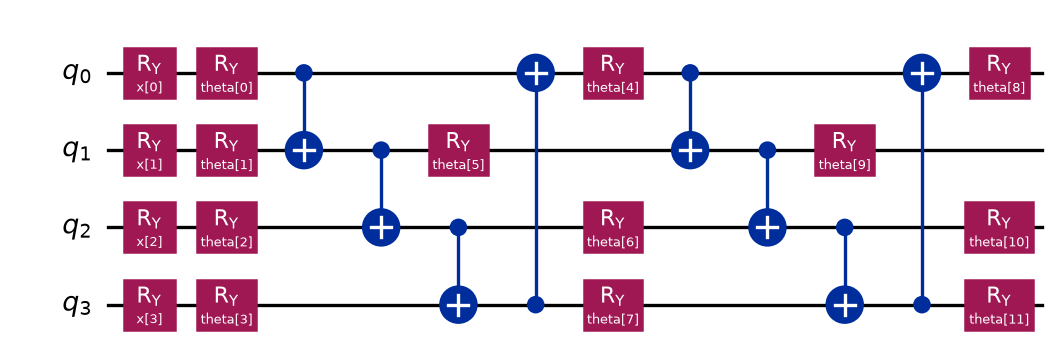

*How to read it:* Read left to right. RY(x) loads a field value; RY(theta) is trained. The filled dot and ⊕ form a CX. This is the actual Qiskit circuit. Independent wire operations may be drawn side by side. Logical depth excludes hardware routing and noise.

In [6]:
ring=TopologyClassifier(LABELS,topology='ring',max_evals=100)
r=ring.resources()
display(pd.DataFrame([{'qubits':r['qubits'],'trainable angles':r['trainable'],
                       'CX gates':r['two_qubit_gates'],'logical depth':r['depth'],
                       'probability passes per gradient':r['probability_passes_per_loss_and_gradient']}]))
fig=ring.circuit.draw(output='mpl',fold=24)
show_figure(fig,'01_ring_circuit','Read left to right. RY(x) loads a field value; RY(theta) is trained. The filled dot and ⊕ form a CX. This is the actual Qiskit circuit. Independent wire operations may be drawn side by side. Logical depth excludes hardware routing and noise.')

The readout groups the 16 basis outcomes by **integer modulo 3** into
`alfalfa, maize, wheat`, then sums each group's probabilities. Groups contain
6, 5 and 5 outcomes. The largest crop probability is the prediction. We use
exact local simulation (`shots=None`), not noisy hardware measurements.
There is no trained classical classifier head.

## 4 — Train or restore the ring model

The **loss** penalizes low probability on the correct crop:
\[
L=-\frac{1}{N}\sum_i\log_2 p(y_i\mid x_i).
\]
For one field, correct-crop probability 0.5 costs 1 bit; 0.25 costs 2 bits.
Lower training loss means a better fit to practice fields, not necessarily
better unseen predictions.

The starter used **COBYLA**, trying nearby angles without derivatives. Ring uses
**L-BFGS-B**, following a gradient (local slope) with a curvature approximation.
Our verified trainer obtains each probability derivative from two circuits shifted
by \(\pm\pi/2\), then applies the chain rule to the loss. Twelve parameters
require **25 probability passes per loss-and-gradient call**. Equal optimizer-call
caps are not equal computational work. Neither optimizer guarantees a global optimum.

The saved model was trained on all 914 fields. Quick mode instead fits preprocessing
only on its 120 selected training fields, evaluating on 180 disjoint training fields.
No validation or test information enters fitting or hyperparameter selection.

In [7]:
archive_runs=json.loads((ARCHIVE/'runs.json').read_text())
ring_records={s:next(r for r in archive_runs if r['topology']=='ring' and r['seed']==s) for s in [0,1,2]}

def restore_ring(seed):
    model=TopologyClassifier(LABELS,topology='ring',max_evals=100)
    with np.load(ARCHIVE/f'ring_seed_{seed}_weights.npz',allow_pickle=False) as w:
        model.model=SimpleNamespace(weights=w['final'].copy())
    model.history=json.loads((ARCHIVE/f'ring_seed_{seed}_history.json').read_text())
    return model

if RUN_MODE=='quick':
    pool,held=train_test_split(np.arange(len(train)),test_size=180,stratify=train.target,random_state=2026)
    fit,_=train_test_split(pool,train_size=120,stratify=train.target.iloc[pool],random_state=2026)
    fit_table,eval_table=train.iloc[fit],train.iloc[held]
    training_prep=preprocessing()
    X=training_prep.fit_transform(fit_table[features].to_numpy())
    V=training_prep.transform(eval_table[features].to_numpy())
    budget=QUICK_MAX_EVALS
    scope='FRESH quick demo: held-out TRAINING fields, not released validation'
elif RUN_MODE=='full':
    fit_table,eval_table=train,validation
    training_prep=prep
    X,V=A,B
    budget=100
    scope='FRESH full-training reproduction on released validation'
else:
    fit_table,eval_table=train,validation
    training_prep=prep
    X,V=A,B
    budget=100
    scope='SAVED historical ring training; FRESH inference replay on released validation'
assert not set(fit_table.sample_id)&set(eval_table.sample_id)
print(scope)
print('Training fields:',len(fit_table),'| Evaluation fields:',len(eval_table),'| Seeds:',TRAINING_SEEDS)

SAVED historical ring training; FRESH inference replay on released validation
Training fields: 914 | Evaluation fields: 150 | Seeds: [0, 1, 2]


In [8]:
models,histories,predictions,metrics_by_seed={},{},{},{}
run_rows,reproduction_checks=[],[]
for seed in TRAINING_SEEDS:
    if RUN_MODE=='saved':
        model=restore_ring(seed)
        fit_seconds=ring_records[seed]['fit_seconds']  # Historical, not a fresh timing.
        origin='LOADED verified ring checkpoint; historical fit time'
    else:
        model=TopologyClassifier(LABELS,topology='ring',max_evals=budget)
        model.fit(X,fit_table.target.to_numpy(),seed=seed)
        fit_seconds=model.fit_seconds
        origin='FRESH ring fit executed in this notebook session'
        np.savez_compressed(OUT/f'ring_seed_{seed}_weights.npz',initial=model.initial_point,final=model.model.weights)
    p=model.predict_proba(V)
    pred=model.labels[p.argmax(axis=1)]
    np.testing.assert_allclose(p[:6],[model.ideal_proba(row) for row in V[:6]],atol=1e-10,rtol=0)
    metrics=score(eval_table.target,pred,LABELS)
    if RUN_MODE!='quick':
        old=pd.read_csv(ARCHIVE/f'ring_seed_{seed}_predictions.csv')
        np.testing.assert_array_equal(old.sample_id,eval_table.sample_id)
        np.testing.assert_array_equal(old.prediction,pred)
        np.testing.assert_allclose(p,old[[f'p_{c}' for c in LABELS]].to_numpy(),atol=1e-10,rtol=0)
        assert metrics==ring_records[seed]['metrics']
        reproduction_checks.append({'seed':seed,'historical_probabilities_labels_metrics_match':True})
    models[seed],histories[seed],predictions[seed],metrics_by_seed[seed]=model,model.history,pred,metrics
    run_rows.append({'seed':seed,'scope':scope,'origin':origin,'accuracy':metrics['accuracy'],
                     'macro_f1':metrics['macro_f1'],'fit_seconds':fit_seconds})
    table=pd.DataFrame({'sample_id':eval_table.sample_id,'target':eval_table.target,'prediction':pred,
                        **{f'p_{c}':p[:,j] for j,c in enumerate(LABELS)}})
    table.to_csv(OUT/f'ring_seed_{seed}_predictions.csv',index=False)
    (OUT/f'ring_seed_{seed}_history.json').write_text(json.dumps(model.history,indent=2))
    print(f'{origin} | seed {seed} | F1={metrics["macro_f1"]:.4f}',flush=True)
joblib.dump(training_prep,OUT/'training_preprocessing.joblib')
results=pd.DataFrame(run_rows)
results.to_csv(OUT/'ring_metrics.csv',index=False)
display(results)

LOADED verified ring checkpoint; historical fit time | seed 0 | F1=0.8943


LOADED verified ring checkpoint; historical fit time | seed 1 | F1=0.8943


LOADED verified ring checkpoint; historical fit time | seed 2 | F1=0.8943


,seed,scope,origin,accuracy,macro_f1,fit_seconds
0,0,SAVED historical ring training; FRESH inferenc...,LOADED verified ring checkpoint; historical fi...,0.893333,0.894346,5.307278
1,1,SAVED historical ring training; FRESH inferenc...,LOADED verified ring checkpoint; historical fi...,0.893333,0.894346,7.264559
2,2,SAVED historical ring training; FRESH inferenc...,LOADED verified ring checkpoint; historical fi...,0.893333,0.894346,5.889624


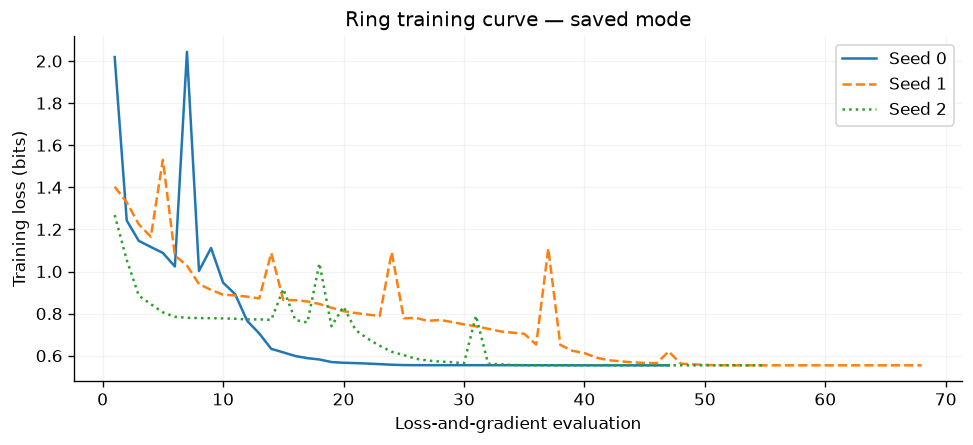

*How to read it:* Lower means a better fit to the training labels. Different seeds start at different angles. Spikes may be trial line-search evaluations rather than accepted steps. Saved mode shows recorded historical curves; quick/full show curves just computed. This is not held-out accuracy.

In [9]:
fig,ax=plt.subplots(figsize=(8,3.6),layout='constrained')
for seed,style in zip(TRAINING_SEEDS,['-','--',':']):
    h=histories[seed]
    ax.plot([r['evaluation'] for r in h],[r['objective_bits'] for r in h],linestyle=style,label=f'Seed {seed}')
ax.set(xlabel='Loss-and-gradient evaluation',ylabel='Training loss (bits)',title=f'Ring training curve — {RUN_MODE} mode')
ax.legend();ax.grid(alpha=.15)
show_figure(fig,'02_training_loss','Lower means a better fit to the training labels. Different seeds start at different angles. Spikes may be trial line-search evaluations rather than accepted steps. Saved mode shows recorded historical curves; quick/full show curves just computed. This is not held-out accuracy.')

## 5 — Evaluate: which crop mistakes remain?

**Accuracy** is correct fields divided by all evaluated fields.
For one crop, **precision** asks “when we predict it, how often are we right?”;
**recall** asks “of the real fields of that crop, how many did we find?”
\[
\mathrm{precision}=\frac{TP}{TP+FP},\quad
\mathrm{recall}=\frac{TP}{TP+FN},\quad
F1=\frac{2PR}{P+R}.
\]
**Macro-F1** averages the three crop F1 scores equally. High wheat recall alone
can conceal many false wheat alarms, so we examine precision and other crops too.

The table below averages seeds, not independent datasets. The confusion matrix
uses one explicitly chosen seed, with no pooling of repeated fields.

,mode,evaluated fields,mean accuracy,mean macro-F1,macro-F1 seed SD,mean fit seconds
0,saved,150,0.893333,0.894346,0.0,6.153821


,precision,recall
crop,,
alfalfa,92.0%,92.0%
maize,97.7%,84.0%
wheat,80.7%,92.0%


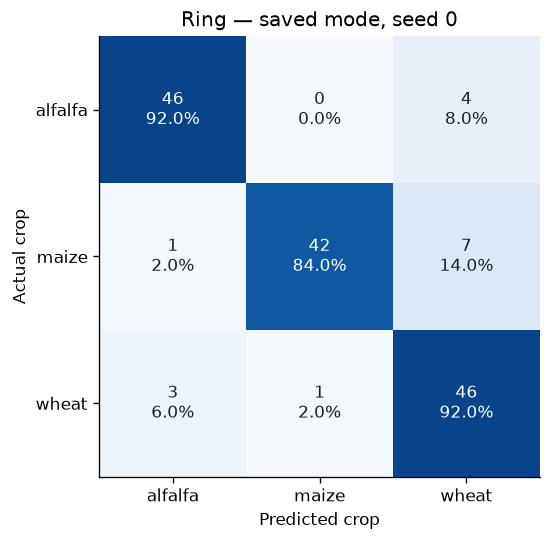

*How to read it:* Rows are actual crops; columns are predictions. Diagonal cells are correct. The maize row/wheat column counts real maize called wheat; the reverse cell is a different error. Percentages divide by actual-crop counts. Quick mode uses its training-only holdout; saved/full use 150 released validation fields.

In [10]:
display(pd.DataFrame([{'mode':RUN_MODE,'evaluated fields':len(eval_table),
                       'mean accuracy':results.accuracy.mean(),'mean macro-F1':results.macro_f1.mean(),
                       'macro-F1 seed SD':results.macro_f1.std(ddof=0),'mean fit seconds':results.fit_seconds.mean()}]))
crop_metrics=pd.DataFrame({'crop':LABELS,
    'precision':np.mean([metrics_by_seed[s]['precision'] for s in TRAINING_SEEDS],axis=0),
    'recall':np.mean([metrics_by_seed[s]['recall'] for s in TRAINING_SEEDS],axis=0)})
display(crop_metrics.set_index('crop').style.format('{:.1%}'))
crop_metrics.to_csv(OUT/'ring_crop_metrics.csv',index=False)

cm=np.asarray(metrics_by_seed[MATRIX_SEED]['confusion'])
fractions=cm/cm.sum(axis=1,keepdims=True)
fig,ax=plt.subplots(figsize=(5.6,4.4),layout='constrained')
ax.imshow(fractions,vmin=0,vmax=1,cmap='Blues')
for i in range(3):
    for j in range(3):
        ax.text(j,i,f'{cm[i,j]}\n{fractions[i,j]:.1%}',ha='center',va='center',
                color='white' if fractions[i,j]>.55 else '#18202a')
ax.set(xticks=range(3),yticks=range(3),xticklabels=LABELS,yticklabels=LABELS,
       xlabel='Predicted crop',ylabel='Actual crop',title=f'Ring — {RUN_MODE} mode, seed {MATRIX_SEED}')
show_figure(fig,'03_confusion_matrix','Rows are actual crops; columns are predictions. Diagonal cells are correct. The maize row/wheat column counts real maize called wheat; the reverse cell is a different error. Percentages divide by actual-crop counts. Quick mode uses its training-only holdout; saved/full use 150 released validation fields.')

For the verified full-trained ring model, the matrix contains 46/50 correct
alfalfa, 42/50 correct maize and 46/50 correct wheat fields. Thus its recall is
92%, 84% and 92%, respectively. The same validation predictions occurred for
all three archived seeds. This stability on one set does not establish stability
on new farms. **Quick-mode results can differ and must be read from their own table.**

**How selection differed:** three-fold training-only cross-validation fits on
two training portions and predicts the third. It refits PCA within each fold.
Our local folds were stratified by crop, not spatial. Their topology mean OOF
macro-F1 was full 0.8688 versus ring 0.8527. Ring's validation mean 0.8943 is
separate historical evidence; we do not use it here to retune or choose seeds.

## 6 — Predict one real validation field

Change the **field index** (0–149) and **seed** (0,1,2), then rerun the next cell.
It shows all 13 measurements, the four prepared values and angles, and a freshly
computed ring prediction. For a consistent demonstration, this always uses the
**verified full-trained ring checkpoint**, even if you ran quick training above.
No field is invented and no checkpoint is adjusted to repair its mistakes.

**Actual validation field `r2_4769de2441c6188e` · true crop: wheat**

,feature,actual measurement
0,B1,586.868537
1,B2,728.447716
2,B3,1046.008811
3,B4,1463.892882
4,B5,1803.853234
5,B6,2198.27336
6,B7,2406.92511
7,B8,2526.913981
8,B8A,2679.04243
9,B9,2780.938094


,component,prepared value,encoded angle (radians)
0,PC1,-0.339563,1.057009
1,PC2,-0.522164,0.817806
2,PC3,-0.167698,1.309819
3,PC4,-0.758130,0.565528


Frozen full-trained ring checkpoint | seed: 0 | prediction: wheat | correct: True


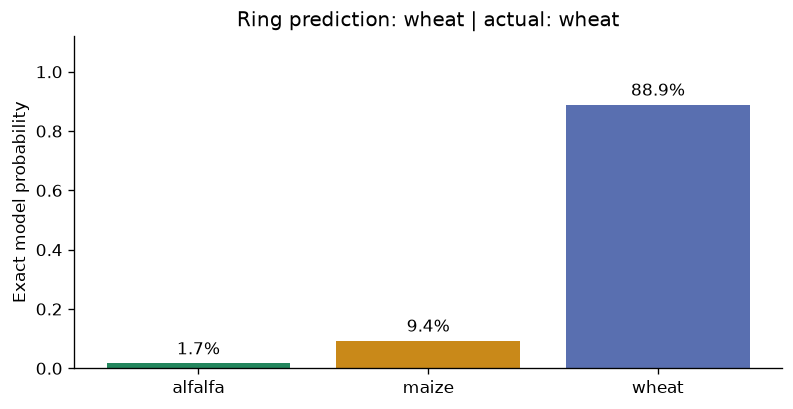

*How to read it:* Each bar is a freshly computed probability from the actual field and frozen ring weights. The largest bar determines the prediction. A large probability can still be wrong; these outputs are not calibrated confidence guarantees.

In [11]:
FIELD_INDEX = 0
FIELD_SEED = 0

if not isinstance(FIELD_INDEX,int) or not 0<=FIELD_INDEX<len(validation):
    raise ValueError('FIELD_INDEX must be an integer from 0 to 149.')
if FIELD_SEED not in [0,1,2]: raise ValueError('FIELD_SEED must be 0, 1 or 2.')
field=validation.iloc[FIELD_INDEX]
prepared=prep.transform(field[features].to_numpy(dtype=float).reshape(1,-1))
encoded=angles(prepared)[0]
demo_model=restore_ring(FIELD_SEED)
probability=demo_model.predict_proba(prepared)[0]
predicted=LABELS[int(probability.argmax())]
old=pd.read_csv(ARCHIVE/f'ring_seed_{FIELD_SEED}_predictions.csv')
assert predicted==old.prediction.iloc[FIELD_INDEX]
display(Markdown(f'**Actual validation field `{field.sample_id}` · true crop: {field.target}**'))
display(pd.DataFrame({'feature':features,'actual measurement':field[features].to_numpy()}))
display(pd.DataFrame({'component':['PC1','PC2','PC3','PC4'],'prepared value':prepared[0],
                      'encoded angle (radians)':encoded}))
print('Frozen full-trained ring checkpoint | seed:',FIELD_SEED,
      '| prediction:',predicted,'| correct:',predicted==field.target)
fig,ax=plt.subplots(figsize=(6.5,3.3),layout='constrained')
bars=ax.bar(LABELS,probability,color=CROP_COLORS)
ax.bar_label(bars,labels=[f'{p:.1%}' for p in probability],padding=3)
ax.set(ylim=(0,1.12),ylabel='Exact model probability',title=f'Ring prediction: {predicted} | actual: {field.target}')
show_figure(fig,f'04_field_{FIELD_INDEX}_seed_{FIELD_SEED}','Each bar is a freshly computed probability from the actual field and frozen ring weights. The largest bar determines the prediction. A large probability can still be wrong; these outputs are not calibrated confidence guarantees.')

## 7 — Brief recap of everything we have done

| Completed work | What we learned |
|---|---|
| Environment, data validation and original circuit | Python 3.12 / Qiskit 2.4.2 work; original data/splits are verified. |
| Original full baseline, 914 fields, seeds 0/1/2 | Local QNN validation mean F1 **0.8557**; original SVM **0.8797**. Local baseline reproduced organizer scores. |
| Tanh scales 1, 0.5, 0.25 | Validation F1 **0.8557, 0.8445, 0.4034**. Gentler scaling separated extreme inputs but sacrificed overall classification; retain scale 1. |
| Native Qiskit, optimizer and depth study A–E | Verified circuit probabilities and gradients; Model D used 12 angles, two blocks and L-BFGS-B. Its linear validation mean F1 was **0.8807**. Training-CV initially selected D. |
| Linear/ring/full topology study | **Full won training-only CV**; **ring led validation at 0.8943**. All models and previous results remain preserved outside this ring-focused notebook. |
| Complete PCA/classical investigation | 4/6/8 PCs gave tuned-SVM training-only F1 **0.8939/0.9095/0.9106**. Small later components contain useful clues. |
| Quantum representation check | First4/4q, selected4/4q, first6/6q gave training-only F1 **0.8688/0.8543/0.8306** with full connectivity. Larger width did not help this tested setup. |

The current training-selected reference remains four PCs/four qubits/full
connectivity. **This notebook intentionally focuses only on ring**, as requested;
it does not replace that selection or start another comparison.

We have not established quantum advantage, geographic transfer or the best
unseen-test architecture. Future re-uploading, feature placement and larger
circuits remain separate hypotheses. None is implemented here. Runtime changes
also reflect input-state caching in the research trainer, not just architecture.

**In VS Code:** open this `.ipynb`, select **Crop challenge** or
`.venv/bin/python`, then **Restart Kernel → Run All**. Leave `saved` initially.
To learn training, choose `quick`; use `full` to reproduce the ring fits. Every
Run All creates a new output folder. The original notebook and old experiments
are unchanged.

In [12]:
changed=[p for p,h in locked.items() if digest(ROOT/p)!=h]
assert not changed, 'Protected files changed: '+', '.join(changed)
audit={'status':'complete','model':'ring only','mode':RUN_MODE,'seeds':TRAINING_SEEDS,
       'branch':branch,'qiskit':version('qiskit'),'python':sys.version.split()[0],
       'scope':scope,'fit_fields':len(fit_table),'evaluation_fields':len(eval_table),
       'optimizer':'L-BFGS-B','maximum_loss_gradient_calls':budget,
       'checkpoint_reproduction_checks':reproduction_checks,'original_files_unchanged':True,
       'test_inference':False,'new_architecture_experiments':False,'protected_sha256':locked}
(OUT/'session.json').write_text(json.dumps(audit,indent=2))
print('Complete: ring notebook ran successfully. Earlier files unchanged.')
print('New plots, metrics and run record:',OUT)

Complete: ring notebook ran successfully. Earlier files unchanged.
New plots, metrics and run record: /Users/alibourak/QiskitFallFest2026/QiskitFallFest_EMSI_QuantumAfrica/outputs/research_notebook/20261121T072304Z_6c73e358
